# Лабораторная работа 3. Построение ETL и ELT-пайплайнов

**Вариант 6**

Ежедневная витрина повторных госпитализаций. Выгрузка → Prefect → проверка CSV и Great Expectations → UPSERT в DuckDB → модели dbt → проверки витрины. Ошибки строк сохраняются в DLQ.

Перед запуском установите зависимости из `requirements.txt`. По умолчанию загрузится CSV с Kaggle. Для локальной копии задайте переменную окружения `LAB3_SOURCE`.

In [1]:
from pathlib import Path
from uuid import uuid4
import os

import matplotlib.pyplot as plt
import pandas as pd

from demo import demonstrate
from warehouse import read_as_of

source = os.getenv("LAB3_SOURCE")
work = Path("tmp") / f"notebook-{uuid4().hex[:8]}"

21:38:26.739 | WARNING | py.warnings - D:\big_data\.runtime\lab3\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm

## 1. Загрузка, оркестрация и контроль качества

Проверка запускает Prefect flow на исходной и повторной выгрузках, затем вводит ошибки и проверяет восстановление. Дополнительно формируются GX Data Docs и каталог dbt.

In [2]:
result = demonstrate(source, work, docs=True)
first, repeat = result["initial"], result["repeated"]
print(f"Строк в выгрузке: {first['input_rows']:,}")
print(f"Загружено: {first['raw_rows']:,}. Отклонено: {first['dlq_rows']}")
print(f"GX до загрузки: {first['gx_before']['passed']}/{first['gx_before']['total']}")
print(f"GX после dbt: {first['gx_after']['passed']}/{first['gx_after']['total']}")

21:38:29.913 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Andre\AppData\Local\Temp\tmpa9um44x7' for ephemeral docs site

21:38:44.977 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Andre\AppData\Local\Temp\tmp_lu57uzv' for ephemeral docs site

21:38:56.007 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Andre\AppData\Local\Temp\tmpkq3ttz_a' for ephemeral docs site

21:39:08.455 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Andre\AppData\Local\Temp\tmpc43albzp' for ephemeral docs site

21:39:13.043 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Andre\AppData\Local\Temp\tmpgy70tfkh' for ephemeral docs site

21:39:39.106 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Andre\AppData\Local\Temp\tmpd4kcq900' for ephemeral docs site

21:39:40.940 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Andre\AppData\Local\Temp\tmpis244rti' for ephemeral docs site

## METRICS ##
IDEMPOTENCY_TEST_PASSED=True
DLQ_ERROR_COUNT=2
DATA_QUALITY_SCORE=1.00
PIPELINE_DURATION_SEC=25.39
Строк в выгрузке: 30,000
Загружено: 30,000. Отклонено: 0
GX до загрузки: 6/6
GX после dbt: 6/6


Контракт CSV отделяет ошибочные строки до загрузки. Great Expectations проверяет входную выборку и готовую витрину в отдельных задачах Prefect.

## 2. Идемпотентность, ошибки и Time Travel

In [3]:
print(f"При повторе обновлено строк: {repeat['changed']}")
print("Проверенные повторы задач:", ", ".join(result["injected_stages"]))
print("Причины DLQ:", result["dlq_by_reason"])
print("Несовместимая схема остановлена:", result["incompatible_blocked"])
print("Проваленная проверка GX:", result["gx_negative_test"]["failed"])
print("Версии возраста тестовой строки:", result["history"])
db = work / "hospital.duckdb"
assert read_as_of(db, 1).equals(read_as_of(db, result["history"]["restored_version"]))

При повторе обновлено строк: 0
Проверенные повторы задач: extract, validate, load, dbt, quality
Причины DLQ: {'incompatible_schema': 1, 'invalid_pressure_format': 1}
Несовместимая схема остановлена: True
Проваленная проверка GX: ['expect_column_values_to_be_between']
Версии возраста тестовой строки: {'old_age': 74, 'updated_age': 75, 'restored_version': 3}


Повторная выгрузка сохраняет объём и версию. При обновлении записи старая версия доступна через `read_as_of`, а восстановление сохраняет историю изменений.

## 3. dbt и готовая витрина

Модели приводят типы, добавляют справочник направлений выписки и агрегируют факты по полу и направлению.

In [4]:
mart = pd.DataFrame(first["mart"])
mart["readmission_pct"] = (100 * mart["readmission_rate"]).round(2)
mart[["discharge_destination", "gender", "encounter_count", "readmitted_count", "readmission_pct"]]

,discharge_destination,gender,encounter_count,readmitted_count,readmission_pct
0,Home,Female,6870,677,9.85
1,Home,Male,6935,678,9.78
2,Home,Other,7072,742,10.49
3,Rehab,Female,2020,347,17.18
4,Rehab,Male,2138,377,17.63
5,Rehab,Other,1938,343,17.70
6,Nursing_Facility,Female,989,173,17.49
7,Nursing_Facility,Male,1024,186,18.16
8,Nursing_Facility,Other,1014,151,14.89


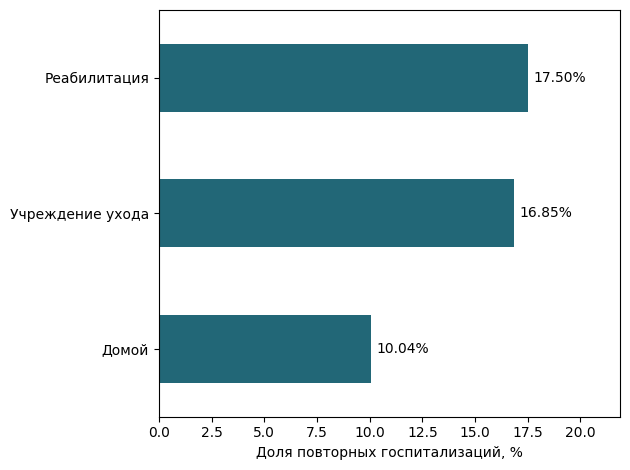

In [5]:
summary = mart.groupby("discharge_destination")[["encounter_count", "readmitted_count"]].sum()
percent = 100 * summary["readmitted_count"] / summary["encounter_count"]
ax = percent.rename(index={"Home": "Домой", "Rehab": "Реабилитация",
                           "Nursing_Facility": "Учреждение ухода"}).sort_values().plot.barh(color="#226777")
ax.set(xlabel="Доля повторных госпитализаций, %", ylabel="")
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
ax.set_xlim(0, percent.max() * 1.25)
plt.tight_layout()
plt.show()

Витрина позволяет сравнить долю повторных поступлений на единой базе расчёта. Даты госпитализаций в CSV отсутствуют, поэтому по этой выгрузке нельзя построить временной ряд.

## 4. Метрики и выпуск

`python release.py` проверяет staging, пробный запуск на выборке, публикацию и автоматический возврат к предыдущей версии при провале smoke-теста. [Отчёт](report.md) содержит результаты и материалы мониторинга.

In [6]:
from demo import print_metrics

print_metrics(result)
pd.Series(first["stage_seconds"], name="Секунды на этапе")

## METRICS ##
IDEMPOTENCY_TEST_PASSED=True
DLQ_ERROR_COUNT=2
DATA_QUALITY_SCORE=1.00
PIPELINE_DURATION_SEC=25.39


extract      0.077
validate     3.148
load         0.937
dbt         12.336
quality      0.629
Name: Секунды на этапе, dtype: float64